In [22]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt 
%matplotlib inline


In [3]:
# read in all the words
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [4]:
len(words)

32033

In [5]:
# build the vocab of chars and mapping to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [6]:
# build the dataset

block_size = 3                                                              # context lenght: how many chars do we take to predict the next one?
X, Y = [], []
for w in words:
    
    # print(w)
    context = [0] * block_size
    for ch in w + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        # print(''.join(itos[i] for i in context), '---->', itos[ix])
        context = context[1:] + [ix]                                        # crop and append
        
X = torch.tensor(X)
Y = torch.tensor(Y)

In [7]:
X.shape, Y.shape

(torch.Size([228146, 3]), torch.Size([228146]))

In [8]:
C = torch.randn((27, 2))

In [9]:
X

tensor([[ 0,  0,  0],
        [ 0,  0,  5],
        [ 0,  5, 13],
        ...,
        [26, 26, 25],
        [26, 25, 26],
        [25, 26, 24]])

In [10]:
emb = C[X]
emb.shape

torch.Size([228146, 3, 2])

In [11]:
W1 = torch.randn((6, 100))
b1 = torch.randn(100)

In [12]:
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)

In [13]:
h

tensor([[ 1.0000, -0.7154,  0.1240,  ...,  0.9997, -0.9990, -0.9331],
        [ 0.9999, -0.6099,  0.0244,  ...,  0.9999, -0.9999, -0.9186],
        [ 1.0000, -0.9818,  0.1426,  ...,  1.0000,  0.9882, -0.9995],
        ...,
        [-0.8122,  0.5843, -0.3639,  ...,  0.9985, -0.0278, -0.9986],
        [-0.8744,  0.8516, -0.6029,  ...,  0.9897, -0.9430, -0.9942],
        [-0.9978,  0.8770, -0.3665,  ...,  0.9991, -0.1714, -0.9981]])

In [14]:
W2 = torch.randn((100, 27))
b2 = torch.randn(27)

In [15]:
logits = h @ W2 + b2

In [16]:
logits.shape

torch.Size([228146, 27])

In [17]:
counts = logits.exp()

In [18]:
probs = counts / counts.sum(1, keepdim=True)

In [19]:
probs[0].sum()

tensor(1.)

In [20]:
loss = -probs[torch.arange(32), Y].log().mean()

IndexError: shape mismatch: indexing tensors could not be broadcast together with shapes [32], [228146]

In [23]:
torch.arange(32)

tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
        18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31])

In [24]:
Y

tensor([ 5, 13, 13,  ..., 26, 24,  0])

In [25]:
loss

NameError: name 'loss' is not defined

# --------------- RESPACTABLE ----------------

In [26]:
X.shape, Y.shape # dataset

(torch.Size([228146, 3]), torch.Size([228146]))

In [27]:
g = torch.Generator().manual_seed(2147483647)              # for reproducibility
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parametres = [C, W1, b1, W2, b2]

In [28]:
sum(p.nelement() for p in parametres) # number of params in total

3481

In [29]:
emb = C[X]                                                  # (32, 3, 2)
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)                   # (32, 100)
logits = h @ W2 + b2                                        # (32, 27)
# counts = logits.exp()
# counts = counts / counts.sum(1, keepdim=True)
# probs = counts / counts.sum(1, keepdim=True)
# loss = -probs[torch.arange(32), Y].log().mean()
loss = F.cross_entropy(logits, Y)
loss


tensor(19.5052)

In [30]:
for p in parametres:
    p.requires_grad = True

In [31]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre
lrs

tensor([0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0011,
        0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011,
        0.0011, 0.0011, 0.0011, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012,
        0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0013, 0.0013, 0.0013,
        0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0014,
        0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014,
        0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015,
        0.0015, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016,
        0.0016, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017,
        0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0019,
        0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0020, 0.0020,
        0.0020, 0.0020, 0.0020, 0.0020, 0.0020, 0.0021, 0.0021, 0.0021, 0.0021,
        0.0021, 0.0021, 0.0021, 0.0022, 

In [32]:
lri = []
lossi = []
for i in range(10000):
    
    # minibatch construct
    ix = torch.randint(0, X.shape[0], (32, ))
    
    # forward pass
    emb = C[X[ix]]                                                  # (32, 3, 2)
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)                   # (32, 100)
    logits = h @ W2 + b2                                        # (32, 27)
    loss = F.cross_entropy(logits, Y[ix])
    

    # backward pass
    for p in parametres:
        p.grad = None
    loss.backward()

    # update
    #lr = lrs[i]
    lr = 0.01
    for p in parametres:
        p.data += -lr * p.grad
        
    # track stats
    # lri.append(lre[i])
    # lossi.append(loss.item())
print(loss.item())

2.5087499618530273


### training split, dev/validation split, test split
### 80%, 10%, 10%

In [33]:
# build the dataset

def build_dataset(words):
    block_size = 3                                                              # context lenght: how many chars do we take to predict the next one?
    X, Y = [], []
    for w in words:
        
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]                                        # crop and append
            
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[:n2])


torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([205280, 3]) torch.Size([205280])


In [34]:
Xtr.shape, Ytr.shape # dataset

(torch.Size([182625, 3]), torch.Size([182625]))

In [74]:
g = torch.Generator().manual_seed(2147483647)              # for reproducibility
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 200), generator=g)
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)
parametres = [C, W1, b1, W2, b2]

In [75]:
sum(p.nelement() for p in parametres)

11897

In [76]:
for p in parametres:
    p.requires_grad = True

In [77]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

In [78]:
lri = []
lossi = []
stepi = []

In [79]:
for i in range(50000):
    
    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (32, ))
    
    # forward pass
    emb = C[Xtr[ix]]                                                  # (32, 3, 2)
    h = torch.tanh(emb.view(-1, 30) @ W1 + b1)                   # (32, 100)
    logits = h @ W2 + b2                                        # (32, 27)
    loss = F.cross_entropy(logits, Ytr[ix])
    

    # backward pass
    for p in parametres:
        p.grad = None
    loss.backward()

    # update
    #lr = lrs[i]
    lr = 0.1
    for p in parametres:
        p.data += -lr * p.grad
        
    # track stats
    # lri.append(lre[i])
    stepi.append(i)
    lossi.append(loss.log10().item())
# print(loss.item())

KeyboardInterrupt: 

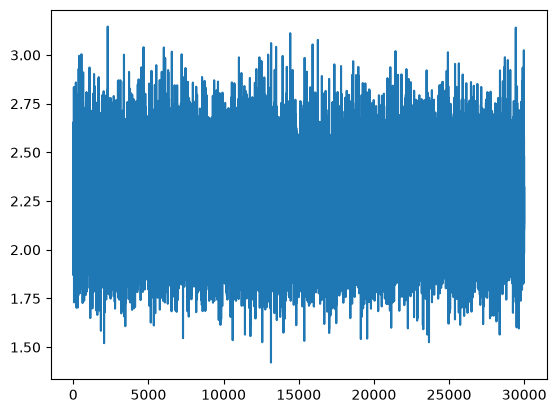

In [ ]:
plt.plot(stepi, lossi)

In [80]:
emb = C[Xdev]                                                  # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1)                   # (32, 100)
logits = h @ W2 + b2                                        # (32, 27)
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.3950, grad_fn=<NllLossBackward0>)

In [81]:
emb = C[Xtr]                                                  # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1)                   # (32, 100)
logits = h @ W2 + b2                                        # (32, 27)
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.3871, grad_fn=<NllLossBackward0>)

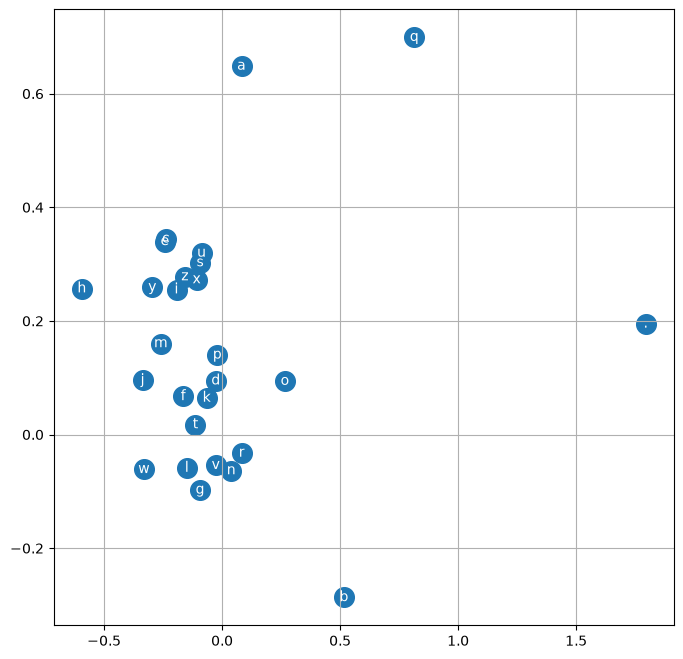

In [82]:
plt.figure(figsize=(8, 8))
plt.scatter(C[:, 0].data, C[:, 1].data, s=200)
for i in range (C.shape[0]):
    plt.text(C[i, 0].item(), C[i, 1].item(), itos[i], ha="center", va="center", color="white")
plt.grid("minor")

## New optimization

In [83]:
for i in range(200000):
    
    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (32, ))
    
    # forward pass
    emb = C[Xtr[ix]]                                                  # (32, 3, 2)
    h = torch.tanh(emb.view(-1, 30) @ W1 + b1)                   # (32, 100)
    logits = h @ W2 + b2                                        # (32, 27)
    loss = F.cross_entropy(logits, Ytr[ix])
    

    # backward pass
    for p in parametres:
        p.grad = None
    loss.backward()

    # update
    #lr = lrs[i]
    lr = 0.1 if i < 100000 else 0.01
    for p in parametres:
        p.data += -lr * p.grad
        
    # track stats
    # lri.append(lre[i])
    stepi.append(i)
    lossi.append(loss.log10().item())
# print(loss.item())

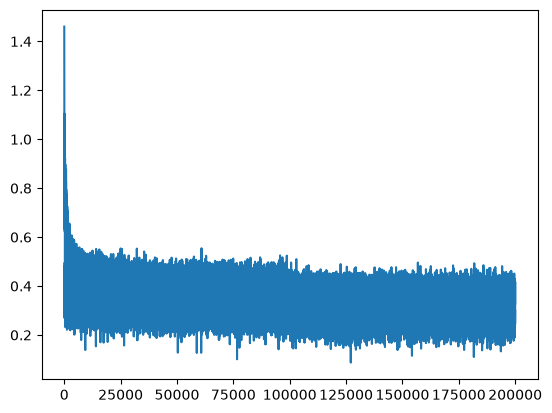

In [84]:
plt.plot(stepi, lossi)